In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp

# Figure 9: copepodTCR predictions for the weak stimulation and absence of signal cases.

Flow cytometry read out, shown as the percentage of GFP-producing activated cells in the
T-cell activation assay for each pool in the design. Pools identified by the Mixture model as activated or
non-activated are shown in green and gray, respectively. Cognate peptides predicted by the decision-tree
algorithm are indicated.

In [2]:
all_together = pd.read_csv('./data/FC_Lu1_Lu2_controls_activation.tsv', sep = '\t')
cpp_scheme = pd.read_csv('./data/peptide-addresses_table.tsv', sep = '\t')
peptides = list(pd.read_csv('./data/peptides.tsv', sep = '\t', header = None)[0])

## pooling parameters
ep_length = 8
n_pools = 12
iters = 4

## A
To test the behavior of the model in the case of a weak activation signal, overgrown Lu1 and Lu2 Jurkat
cell lines from Figure 3 were stimulated with combinatorial pools. The overgrown cell lines showed more
than five-fold reduced activation levels compared to Figure 3, but the model still predicted the correct
target peptides.

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 8 seconds.
There were 488 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")


Posterior mean of p: 0.575
Drop-out was detected
Cognate peptides: ['NVTWFHAIHVSGTNGTK', 'LPFFSNVTWFHAIHVSG']
Peptide candidates: ['NVTWFHAIHVSGTNGTK', 'LPFFSNVTWFHAIHVSG', 'TQDLFLPFFSNVTWFHA']


<Axes: title={'center': 'NVTWFHAIHVSGTNGTK or LPFFSNVTWFHAIHVSG'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

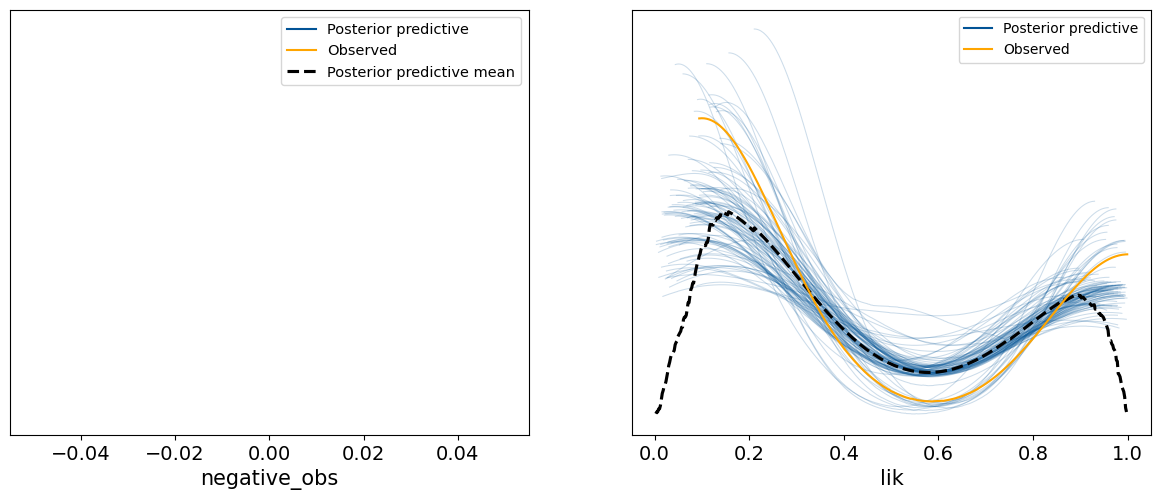

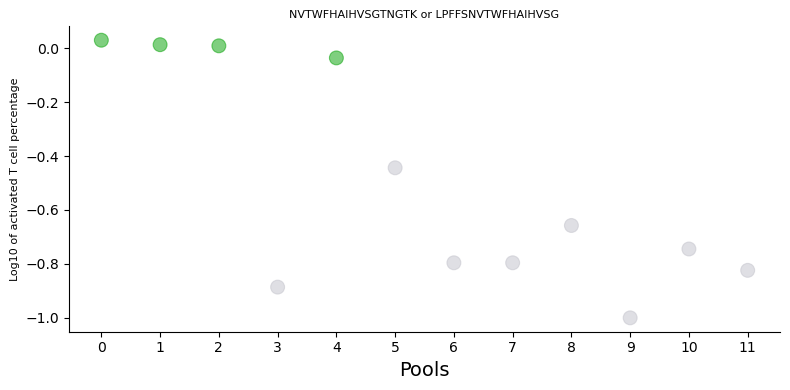

In [3]:
## Lu1, mix 1
mask = (all_together['Line'] == 'Lu1') & (all_together['Mix'] == 'mix1')
subset = all_together[(mask & (all_together['Pool'] != 'unstim'))]

### preparing data for the model
obs = list(subset['Percentage'])
### pool indices
#### (in our scheme pool indices start with 0, but in the experimental results table with 1)
inds = np.array(list(map(int, subset['Pool']))) - 1
### negative control
neg_control = [all_together['Percentage'][mask & (all_together['Pool'] == 'unstim')]]

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_control, neg_share = neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

cpp.poolplot(probs, obs, inds, most)

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 12 seconds.
There were 112 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")


Posterior mean of p: 0.579
No drop-outs were detected
Cognate peptides: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']
Peptide candidates: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']


<Axes: title={'center': 'LPFFSNVTWFHAIHVSG or NVTWFHAIHVSGTNGTK'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

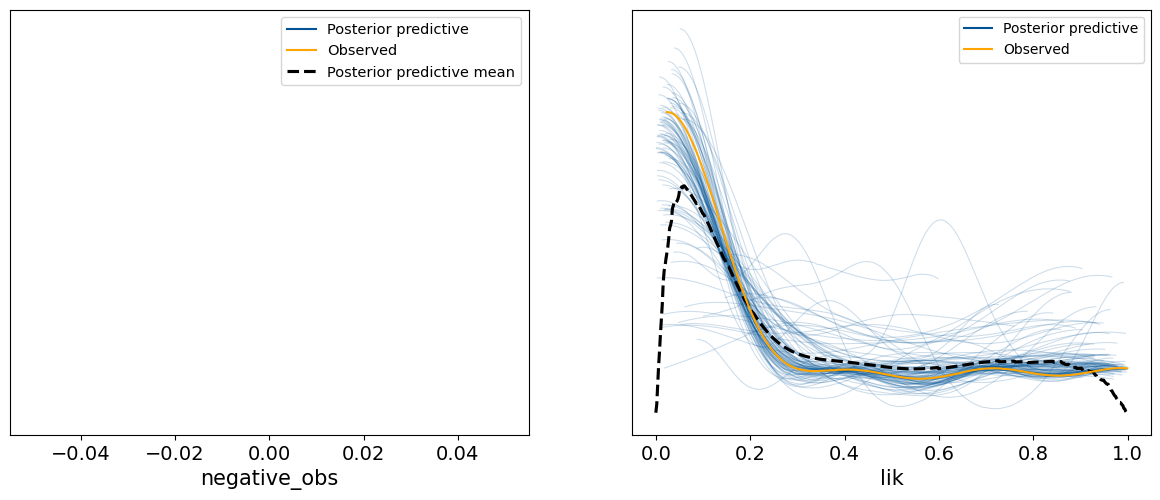

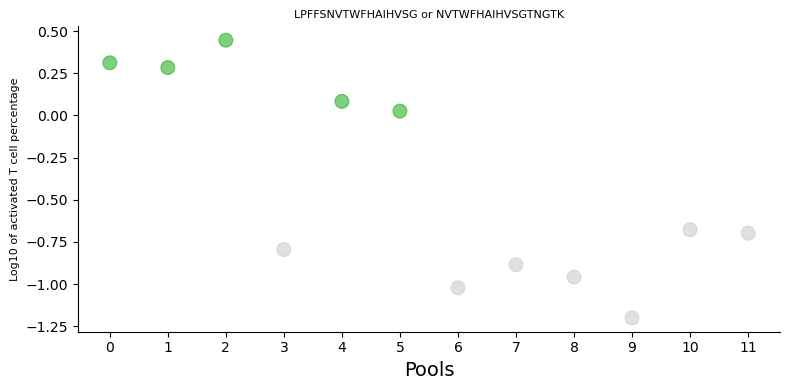

In [4]:
## Lu2, mix 1
mask = (all_together['Line'] == 'Lu2') & (all_together['Mix'] == 'mix1')
subset = all_together[(mask & (all_together['Pool'] != 'unstim'))]

### preparing data for the model
obs = list(subset['Percentage'])
### pool indices
#### (in our scheme pool indices start with 0, but in the experimental results table with 1)
inds = np.array(list(map(int, subset['Pool']))) - 1
### negative control
neg_control = [all_together['Percentage'][mask & (all_together['Pool'] == 'unstim')]]

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_control, neg_share = neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

cpp.poolplot(probs, obs, inds, most)

## B
To test the behavior of the model in the absence of a positive signal we co-cultured
the cell lines with DRB1:16-negative APCs pulsed with the combinatorial pools. As expected, the model
classified all pools as non-activated for Lu1, but surprisingly identified a weak signature of the target
peptide for the higher-affinity Lu2 TCR, suggesting low-level presentation of this antigen by other MHCII
alleles.

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 9 seconds.
There were 72 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")


Posterior mean of p: 0.585
Zero pools were activated
Cognate peptides: []
Peptide candidates: []


<Axes: xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

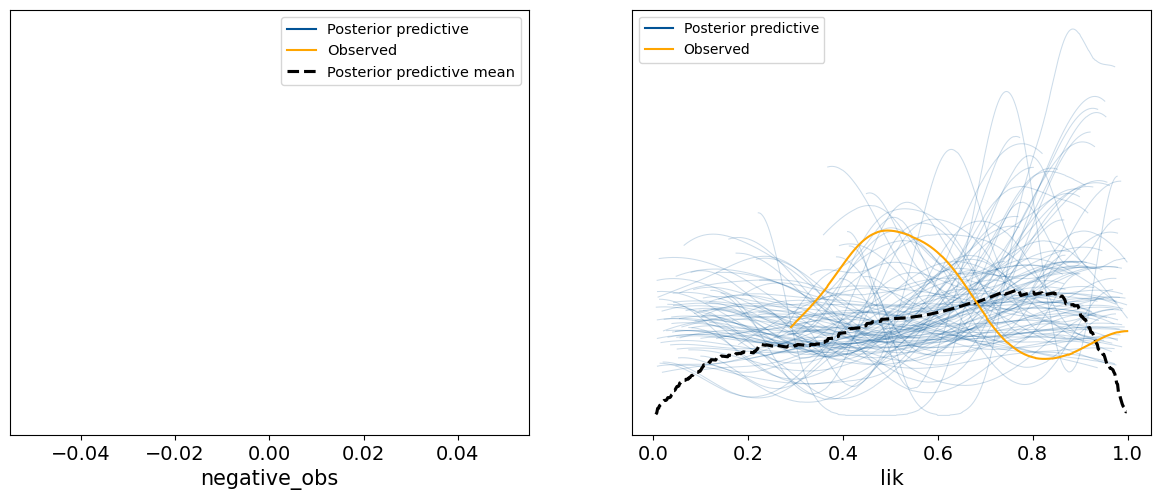

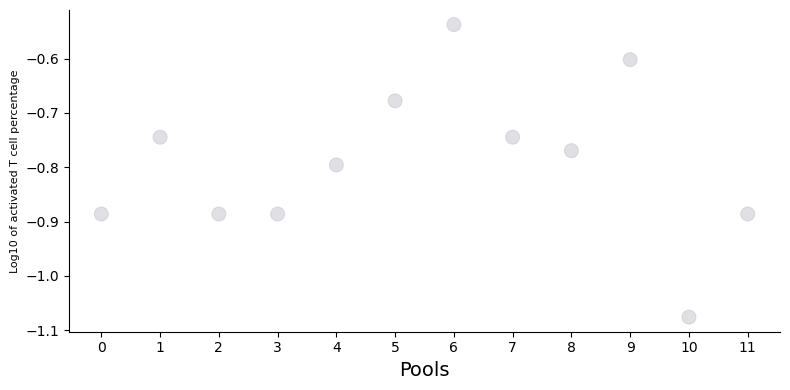

In [5]:
## Lu1, mix 2
mask = (all_together['Line'] == 'Lu1') & (all_together['Mix'] == 'mix2')
subset = all_together[(mask & (all_together['Pool'] != 'unstim'))]

### preparing data for the model
obs = list(subset['Percentage'])
### pool indices
#### (in our scheme pool indices start with 0, but in the experimental results table with 1)
inds = np.array(list(map(int, subset['Pool']))) - 1
### negative control
neg_control = [all_together['Percentage'][mask & (all_together['Pool'] == 'unstim')]]

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_control, neg_share = neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

cpp.poolplot(probs, obs, inds, most)

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 10 seconds.
There were 49 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/density_utils.py:488: UserWarning: Your data appears to have a single value or no finite values
  warnings.warn("Your data appears to have a single value or no finite values")


Posterior mean of p: 0.583
Drop-out was detected
Cognate peptides: ['NVTWFHAIHVSGTNGTK', 'LPFFSNVTWFHAIHVSG']
Peptide candidates: ['DSKTQSLLIVNNATNVV', 'VTLADAGFIKQYGDCLG', 'SFIEDLLFNKVTLADAG', 'LLFNKVTLADAGFIKQY', 'IGAEHVNNSYECDIPIG', 'SLLIVNNATNVVIKVCE', 'GKQGNFKNLREFVFKNI', 'NNATNVVIKVCEFQFCN', 'AGFIKQYGDCLGDIAAR', 'VNNSYECDIPIGAGICA', 'LMDLEGKQGNFKNLREF', 'SFGGVSVITPGTNTSNQ', 'TLVKQLSSNFGAISSVL', 'GTNTSNQVAVLYQDVNC', 'GAISSVLNDILSRLDKV', 'LSSNFGAISSVLNDILS', 'NVTWFHAIHVSGTNGTK', 'LPFFSNVTWFHAIHVSG', 'VSQPFLMDLEGKQGNFK', 'TQDLFLPFFSNVTWFHA', 'SVITPGTNTSNQVAVLY']


<Axes: title={'center': 'NVTWFHAIHVSGTNGTK or LPFFSNVTWFHAIHVSG'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

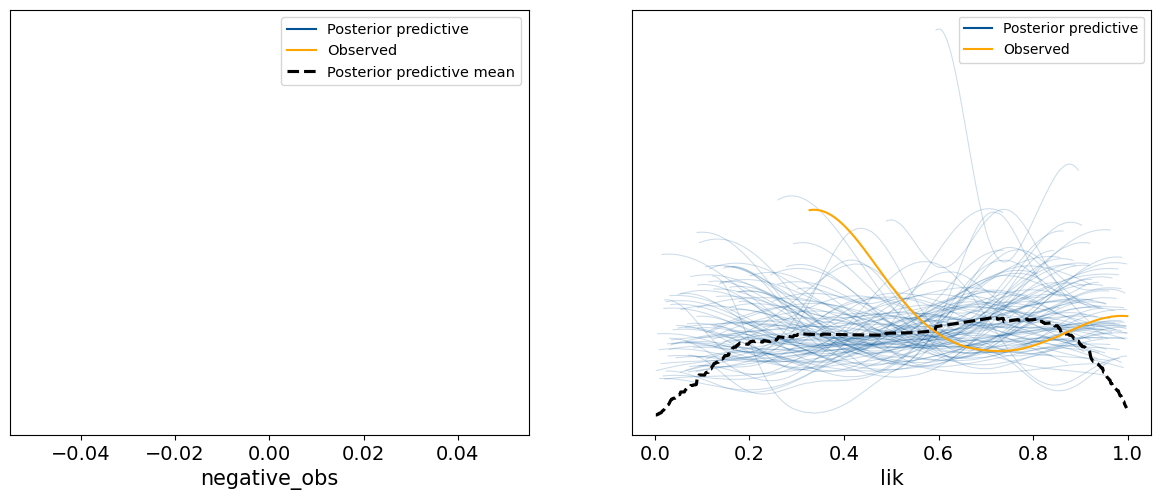

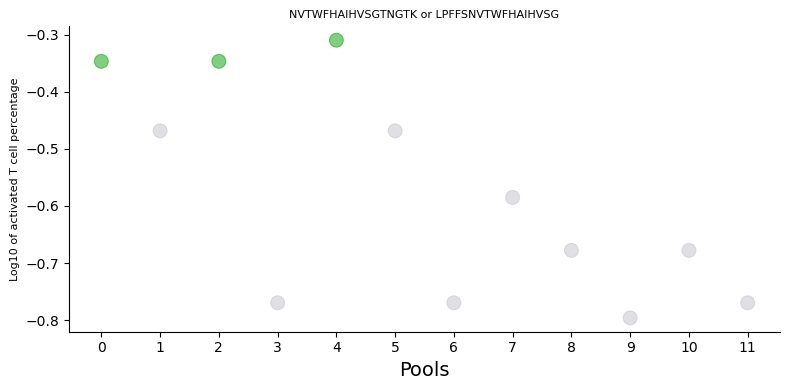

In [6]:
## Lu2, mix 2
mask = (all_together['Line'] == 'Lu2') & (all_together['Mix'] == 'mix2')
subset = all_together[(mask & (all_together['Pool'] != 'unstim'))]

### preparing data for the model
obs = list(subset['Percentage'])
### pool indices
#### (in our scheme pool indices start with 0, but in the experimental results table with 1)
inds = np.array(list(map(int, subset['Pool']))) - 1
### negative control
neg_control = [all_together['Percentage'][mask & (all_together['Pool'] == 'unstim')]]

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_control, neg_share = neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

cpp.poolplot(probs, obs, inds, most)